# Try example detect/seg
- trying to adapt "Track on Radar data, Segment on satellite data" from tobac examle nbooks
- Radar => IMERG
- Sat => Nasa-Tb

In [1]:
import numpy as np
import xarray as xr

# 
from pathlib import Path

# Import tobac itself:
import tobac
import tobac.utils

print("using tobac version", str(tobac.__version__))

# load tools
import sys 
sys.path.append("../tools")
import handle_OBS_data

/home/b/b383071/.conda/envs/ma_thesis/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)
/home/b/b383071/.conda/envs/ma_thesis/lib/python3.11/site-packages/tobac/utils/decorators.py:536: UserWarning: Numba not able to be imported; periodic boundary calculations will be slower.Exception raised: ImportError('Numba needs NumPy 2.3 or less. Got NumPy 2.4.')
  warnings.warn(


using tobac version 1.6.2


In [2]:
#Set up directory to save output and plots:
savedir=Path("../output/tobactryoutsdata")
if not savedir.is_dir():
    savedir.mkdir()
plot_dir=Path("../output/plots")
if not plot_dir.is_dir():
    plot_dir.mkdir()

# load data

In [3]:
# set date
date = "2006-06-06-1800"

# load data (load, allign coords, selects Tb and precip variable)
tb = handle_OBS_data.load_clean_crop_tb(date,32)

# load data
imerg = handle_OBS_data.load_clean_crop_imerg(date,32)

#tb, imerg

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Tb data loaded, cropped, 'Tb' selected


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

IMERG data loaded, cleaned, cropped, 'precipitation' selected


/work/bb1376/user/leonie/MA/nbooks/../tools/get_data.py:138: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  imerg_clean["time"] = imerg_clean.indexes["time"].to_datetimeindex(time_unit = "ns")


In [4]:
tb

<xarray.DataArray 'Tb' (time: 1, lat: 1758, lon: 9896)> Size: 70MB
dask.array<getitem, shape=(1, 1758, 9896), dtype=float32, chunksize=(1, 879, 2474), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 8B 2006-06-06T18:00:00
  * lat      (lat) float32 7kB -31.96 -31.93 -31.89 -31.86 ... 31.89 31.93 31.96
  * lon      (lon) float32 40kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
Attributes:
    units:          K
    standard_name:  brightness_temperature

In [5]:
imerg

<xarray.DataArray 'precipitation' (time: 1, lat: 640, lon: 3600)> Size: 9MB
dask.array<getitem, shape=(1, 640, 3600), dtype=float32, chunksize=(1, 640, 145), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 8B 2006-06-06T18:00:00
  * lat      (lat) float32 3kB -31.95 -31.85 -31.75 -31.65 ... 31.75 31.85 31.95
  * lon      (lon) float32 14kB -179.9 -179.9 -179.8 ... 179.8 179.8 179.9
Attributes:
    DimensionNames:    time,lon,lat
    Units:             mm/hr
    units:             mm/hr
    CodeMissingValue:  -9999.9
    LongName:          \nComplete merged microwave-infrared (gauge-adjusted)\...

# Prepare Data
In the next steps, we
- regular grid  
- convert the dataset into an Iris Cube (which is taken as tobac input)


In [6]:
tb_iris = tb.to_iris()
imerg_iris = imerg.to_iris()
imerg_iris

<iris 'Cube' of precipitation / (mm/hr) (time: 1; latitude: 640; longitude: 3600)>

# tobac cloud tracking
### Feature detection
use multiple trheshold in the radar (imerg) data

In [7]:
np.nanmax(imerg_iris.data)


np.float32(70.189995)

In [8]:
# set horizontal grid spacing [m] and temporal resolution [s]
dxy = 4000
#dt = 1800 # 0.5h # for linking

# detection para (imerg)
feature_detection_params = dict()
feature_detection_params["threshold"] = [5,20,40]
feature_detection_params["target"] = "maximum"
#feature_detection_params["position_threshold"] = "weighted_diff"
#feature_detection_params["n_erosion_threshold"] = 2
#feature_detection_params["sigma_threshold"] = 1
feature_detection_params["n_min_threshold"] = 4
# from CCIC example (threshold, target, n_min_threshold = 1000) 
#feature_detection_params['statistic'] = {"feature_min_iwp": np.nanmin, 'feature_max_iwp': np.nanmax, 'feature_mean_iwp': np.nanmean}

In [9]:
# Perform feature detection:
print('starting feature detection')
imerg_features = tobac.feature_detection.feature_detection_multithreshold(
    imerg_iris, dxy, **feature_detection_params
)
imerg_features.to_hdf(savedir / 'Features.h5', key= 'table')
print('feature detection performed and saved')
imerg_features

starting feature detection
feature detection performed and saved


/tmp/ipykernel_144123/4022508793.py:6: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['time'], dtype='str')]

  imerg_features.to_hdf(savedir / 'Features.h5', key= 'table')


,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,latitude,longitude
0,0,8,26.575758,346.909091,33,5,1,2006-06-06 18:00:00,2006-06-06 18:00:00,-29.292424,-145.259090
1,0,11,34.416667,338.361111,36,5,2,2006-06-06 18:00:00,2006-06-06 18:00:00,-28.508332,-146.113886
2,0,13,44.200000,1471.800000,10,5,3,2006-06-06 18:00:00,2006-06-06 18:00:00,-27.529999,-32.770000
3,0,14,48.642857,1252.714286,14,5,4,2006-06-06 18:00:00,2006-06-06 18:00:00,-27.085714,-54.678570
4,0,18,55.500000,1249.000000,6,5,5,2006-06-06 18:00:00,2006-06-06 18:00:00,-26.399999,-55.049999
...,...,...,...,...,...,...,...,...,...,...,...
336,0,788,569.666667,3149.166667,6,20,337,2006-06-06 18:00:00,2006-06-06 18:00:00,25.016666,134.966665
337,0,798,600.200000,3212.200000,5,20,338,2006-06-06 18:00:00,2006-06-06 18:00:00,28.069999,141.269998
338,0,800,631.200000,1102.600000,5,20,339,2006-06-06 18:00:00,2006-06-06 18:00:00,31.170000,-69.690001
339,0,802,236.600000,2840.400000,5,40,340,2006-06-06 18:00:00,2006-06-06 18:00:00,-8.290000,104.089995


In [10]:
#imerg_features.head()
imerg_features.columns

Index(['frame', 'idx', 'hdim_1', 'hdim_2', 'num', 'threshold_value', 'feature',
       'time', 'timestr', 'latitude', 'longitude'],
      dtype='str')

In [11]:
# filter for thres>20
filtered_imerg_features = imerg_features[imerg_features["threshold_value"] >= 40]
filtered_imerg_features

,frame,idx,hdim_1,hdim_2,num,threshold_value,feature,time,timestr,latitude,longitude
339,0,802,236.6,2840.4,5,40,340,2006-06-06 18:00:00,2006-06-06 18:00:00,-8.29,104.089995
340,0,810,414.5,689.0,6,40,341,2006-06-06 18:00:00,2006-06-06 18:00:00,9.50,-111.049995


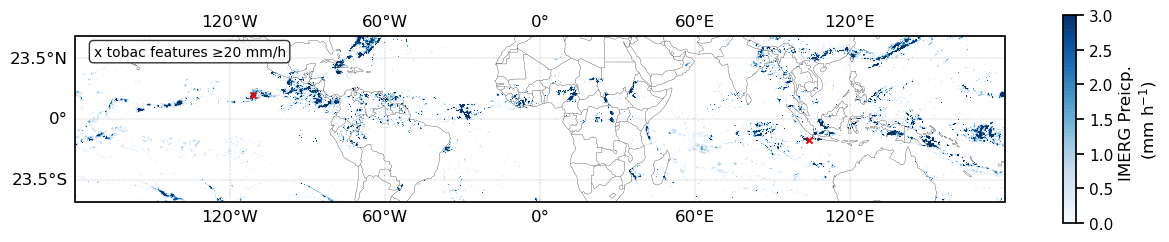

In [13]:
#plot 
import plots_mapping
import seaborn as sns
import cartopy.crs as ccrs


sns.set_context("notebook")

ax, pcm = plots_mapping.plot_imerg_map_simple_fast(imerg, cmap= plots_mapping.precip_colormap())

def add_features_to_plot_fast(data,label_features): 
    ax.scatter(
        data["longitude"],
        data["latitude"],
        s=20,<
        c="red",
        marker="x",
        transform=ccrs.PlateCarree(),  # to match map simple
        zorder=10
    )
    
    # manual "legend" so plotting is faster
    textstr = f"x {label_features}"
    props = dict(boxstyle='round', facecolor='white', alpha=0.8)
    
    ax.text(
        0.02, 0.95,        # x, y in axes fraction coordinates
        textstr,
        transform=ax.transAxes,
        fontsize=10,
        color= "black",
        verticalalignment='top',
        bbox=props
    )
    return ax
ax = add_features_to_plot_fast(filtered_imerg_features,label_features="tobac features ≥20 mm/h")

# Segmentation 

In [14]:
tb_iris.coords()

/home/b/b383071/.conda/envs/ma_thesis/lib/python3.11/site-packages/iris/common/mixin.py:206: FutureWarning: You are using legacy date precision for Iris units - max precision is seconds. In future, Iris will use microsecond precision - available since cf-units version 3.3 - which may affect core behaviour. To opt-in to the new behaviour, set `iris.FUTURE.date_microseconds = True`.
  warnings.warn(message, category=FutureWarning)


[<DimCoord: time / (days since 1970-01-01)  [2006-06-06 18:00:00]>,
 <DimCoord: latitude / (degrees_north)  [-31.965, ...]  shape(1758,)>,
 <DimCoord: longitude / (degrees_east)  [-179.982, ...]  shape(9896,)>]

In [15]:
parameters_segmentation = dict()
parameters_segmentation["method"] = "watershed"
parameters_segmentation["threshold"] = 240
parameters_segmentation["target"] = "minimum"
# parameters_segmentation["seed_3D_flag"] = "box"
# parameters_segmentation["seed_3D_size"] = 5

In [16]:
# Perform segmentation and save results:
print('Starting segmentation.')
segmentation_mask, segmentation_features = tobac.segmentation.segmentation(
    imerg_features, tb_iris, dxy=2000, **parameters_segmentation
)


Starting segmentation.


/home/b/b383071/.conda/envs/ma_thesis/lib/python3.11/site-packages/tobac/segmentation/watershed_segmentation.py:1264: UserWarning: As of v1.6.0, segmentation with time length 1 will return time as a coordinate instead of dropping it (i.e., output will now be 1xMxN instead of MxN). 
  warnings.warn(


In [30]:
print('segmentation performed, start saving results to files')
tmp = xr.DataArray.from_iris(segmentation_mask)
tmp.to_netcdf(savedir / 'Mask_Segmentation_sat.nc', encoding={"segmentation_mask":{"zlib":True, "complevel":4}})

#tmp = xr.DataArray.from_iris(segmentation_features)
segmentation_features.to_hdf(savedir / 'Features_sat.h5', key = 'table')
print('segmentation performed and saved')

segmentation performed, start saving results to files


sh: getfattr: command not found


segmentation performed and saved


/tmp/ipykernel_144123/3538867191.py:6: PerformanceWarning: 
your performance may suffer as PyTables will pickle object types that it cannot
map directly to c-types [inferred_type->mixed,key->block3_values] [items->Index(['time'], dtype='str')]

  segmentation_features.to_hdf(savedir / 'Features_sat.h5', key = 'table')


AttributeError: 'Cube' object has no attribute 'values'

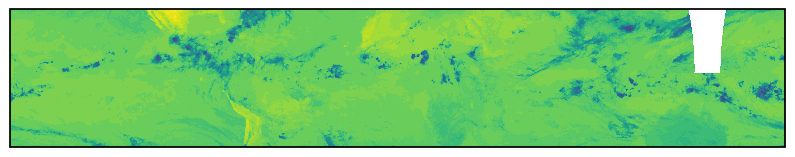

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

# extract coordinates
lats = tb_iris.coord('latitude').points
lons = tb_iris.coord('longitude').points

# choose time
t = 0

fig = plt.figure(figsize=(10, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# background field (brightness temperature)
cf = ax.contourf(
    lons,
    lats,
    tb_iris[t].data,
    levels=31,
    cmap='viridis',
    transform=ccrs.PlateCarree()
)

# plot segmentation outlines
unique_seg = np.unique(segmentation_mask.values)

for seg in unique_seg:
    if seg <= 0:
        continue

    mask = (segmentation_mask == seg).isel(time=t).values.astype(int)

    ax.contour(
        lons,
        lats,
        mask,
        levels=[0.9, 1],
        linewidths=1.5,
        transform=ccrs.PlateCarree()
    )

ax.coastlines()
plt.colorbar(cf, label='Brightness Temperature')
plt.title('TOBAC Segmentation on tb_iris')
plt.show()
on_mask.coords